# Graph Neural Networks for Fraud Detection (Elliptic Bitcoin dataset)
**Goal:** flag illicit transactions in a payment graph, and compare graph models (GCN, GraphSAGE) against strong tabular baselines (Logistic Regression, XGBoost).

**Data:** Elliptic dataset — 203,769 Bitcoin transactions (nodes), 234,355 payment flows (edges), 165 features, labels: illicit / licit / unknown.
Split is **temporal** (train on time steps 1–34, test on 35–49), which mimics real deployment: train on the past, predict the future.

**Main metric:** F1, precision, recall and PR-AUC for the *illicit* class (accuracy is misleading because only ~10% of labelled nodes are illicit).

In [1]:
# Run this first (Colab: Runtime > Change runtime type > GPU is optional; CPU works)
!pip -q install torch_geometric

In [2]:
import numpy as np, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.datasets import EllipticBitcoinDataset
from torch_geometric.transforms import ToUndirected
from torch_geometric.nn import GCNConv, SAGEConv
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score, precision_recall_curve
from xgboost import XGBClassifier

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

ds = EllipticBitcoinDataset(root='data/elliptic')
data = ToUndirected()(ds[0])
print(data)
y = data.y  # 0 = licit, 1 = illicit, 2 = unknown
for name, m in [('train', data.train_mask), ('test', data.test_mask)]:
    print(f"{name}: {int(m.sum())} labelled nodes, illicit share = {(y[m]==1).float().mean():.3f}")
print('unknown (unlabelled) nodes:', int((y==2).sum()))

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Processing...
Done!


Data(x=[203769, 165], edge_index=[2, 468710], y=[203769], train_mask=[203769], test_mask=[203769])
train: 29894 labelled nodes, illicit share = 0.116
test: 16670 labelled nodes, illicit share = 0.065
unknown (unlabelled) nodes: 157205


## 1. Train / validation / test split
Hold out 15% of the training nodes as validation (used to pick the best epoch and the decision threshold). The test set is never touched until the end.

In [3]:
train_idx_all = data.train_mask.nonzero().view(-1)
perm = train_idx_all[torch.randperm(len(train_idx_all), generator=torch.Generator().manual_seed(SEED))]
n_val = int(0.15 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]
test_idx = data.test_mask.nonzero().view(-1)

# Scale features using TRAINING nodes only (avoids data leakage)
scaler = StandardScaler().fit(data.x[train_idx].numpy())
X = torch.tensor(scaler.transform(data.x.numpy()), dtype=torch.float)
yn = y.numpy()
print(len(train_idx), len(val_idx), len(test_idx))

25410 4484 16670


## 2. Helper: evaluate with a tuned threshold
Fraud teams choose a threshold based on the cost of missed fraud vs. false alarms. Here we pick the threshold that maximises F1 on validation, then apply it unchanged to test.

In [4]:
def best_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2*prec*rec/(prec+rec+1e-12)
    i = np.nanargmax(f1[:-1])
    return thr[i]

def report(name, y_true, p, thr):
    pred = (p >= thr).astype(int)
    r = dict(model=name, threshold=round(float(thr),3),
             precision=precision_score(y_true, pred), recall=recall_score(y_true, pred),
             f1=f1_score(y_true, pred), pr_auc=average_precision_score(y_true, p))
    print({k: (round(v,3) if isinstance(v,float) else v) for k,v in r.items()})
    return r

results, curves = [], {}
tr, va, te = train_idx.numpy(), val_idx.numpy(), test_idx.numpy()

## 3. Baselines (no graph): Logistic Regression and XGBoost

In [5]:
Xn = X.numpy()
lr = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xn[tr], yn[tr])
p_val, p_te = lr.predict_proba(Xn[va])[:,1], lr.predict_proba(Xn[te])[:,1]
results.append(report('LogReg', yn[te], p_te, best_threshold(yn[va], p_val))); curves['LogReg']=p_te

spw = (yn[tr]==0).sum()/(yn[tr]==1).sum()   # handle class imbalance
xgb = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='aucpr', random_state=SEED)
xgb.fit(Xn[tr], yn[tr])
p_val, p_te = xgb.predict_proba(Xn[va])[:,1], xgb.predict_proba(Xn[te])[:,1]
results.append(report('XGBoost', yn[te], p_te, best_threshold(yn[va], p_val))); curves['XGBoost']=p_te

{'model': 'LogReg', 'threshold': 0.814, 'precision': 0.227, 'recall': 0.704, 'f1': 0.343, 'pr_auc': np.float64(0.286)}
{'model': 'XGBoost', 'threshold': 0.615, 'precision': 0.872, 'recall': 0.734, 'f1': 0.797, 'pr_auc': np.float64(0.807)}


## 4. Graph Neural Networks: GCN and GraphSAGE
A GNN lets each transaction 'look at' the transactions it is connected to, so suspicious neighbourhoods raise its risk score. Class-weighted loss handles imbalance; early stopping uses validation PR-AUC.

In [6]:
class GNN(torch.nn.Module):
    def __init__(self, conv, in_dim, hid=64, dropout=0.5):
        super().__init__()
        self.c1, self.c2 = conv(in_dim, hid), conv(hid, 2)
        self.dropout = dropout
    def forward(self, x, edge_index):
        h = F.relu(self.c1(x, edge_index))
        h = F.dropout(h, self.dropout, self.training)
        return self.c2(h, edge_index)

def train_gnn(conv, name, epochs=300, patience=40):
    torch.manual_seed(SEED)
    model = GNN(conv, X.size(1)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    x, ei, yy = X.to(device), data.edge_index.to(device), y.to(device)
    w = torch.tensor([1.0, float(spw)], device=device)
    best, best_state, wait = -1, None, 0
    for ep in range(1, epochs+1):
        model.train(); opt.zero_grad()
        out = model(x, ei)
        loss = F.cross_entropy(out[train_idx], yy[train_idx], weight=w)
        loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            p = F.softmax(model(x, ei), 1)[:,1].cpu().numpy()
        ap = average_precision_score(yn[va], p[va])
        if ap > best: best, best_state, wait = ap, {k:v.clone() for k,v in model.state_dict().items()}, 0
        else: wait += 1
        if ep % 25 == 0: print(f'{name} epoch {ep}: loss {loss.item():.4f}, val PR-AUC {ap:.3f}')
        if wait >= patience: print(f'early stop at epoch {ep}'); break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        p = F.softmax(model(x, ei), 1)[:,1].cpu().numpy()
    results.append(report(name, yn[te], p[te], best_threshold(yn[va], p[va]))); curves[name]=p[te]
    return model

gcn = train_gnn(GCNConv, 'GCN')
sage = train_gnn(SAGEConv, 'GraphSAGE')

GCN epoch 25: loss 0.2420, val PR-AUC 0.809
GCN epoch 50: loss 0.1963, val PR-AUC 0.860
GCN epoch 75: loss 0.1707, val PR-AUC 0.881
GCN epoch 100: loss 0.1534, val PR-AUC 0.893
GCN epoch 125: loss 0.1420, val PR-AUC 0.902
GCN epoch 150: loss 0.1283, val PR-AUC 0.908
GCN epoch 175: loss 0.1237, val PR-AUC 0.912
GCN epoch 200: loss 0.1171, val PR-AUC 0.917
GCN epoch 225: loss 0.1140, val PR-AUC 0.929
GCN epoch 250: loss 0.1086, val PR-AUC 0.926
GCN epoch 275: loss 0.1048, val PR-AUC 0.929
GCN epoch 300: loss 0.1031, val PR-AUC 0.926
{'model': 'GCN', 'threshold': 0.711, 'precision': 0.832, 'recall': 0.416, 'f1': 0.555, 'pr_auc': np.float64(0.609)}
GraphSAGE epoch 25: loss 0.1728, val PR-AUC 0.921
GraphSAGE epoch 50: loss 0.1114, val PR-AUC 0.952
GraphSAGE epoch 75: loss 0.0819, val PR-AUC 0.965
GraphSAGE epoch 100: loss 0.0699, val PR-AUC 0.969
GraphSAGE epoch 125: loss 0.0624, val PR-AUC 0.971
GraphSAGE epoch 150: loss 0.0553, val PR-AUC 0.973
GraphSAGE epoch 175: loss 0.0502, val PR-AUC

## 5. Results

,threshold,precision,recall,f1,pr_auc
model,,,,,
LogReg,0.814,0.227,0.704,0.343,0.286
XGBoost,0.615,0.872,0.734,0.797,0.807
GCN,0.711,0.832,0.416,0.555,0.609
GraphSAGE,0.716,0.799,0.613,0.694,0.678


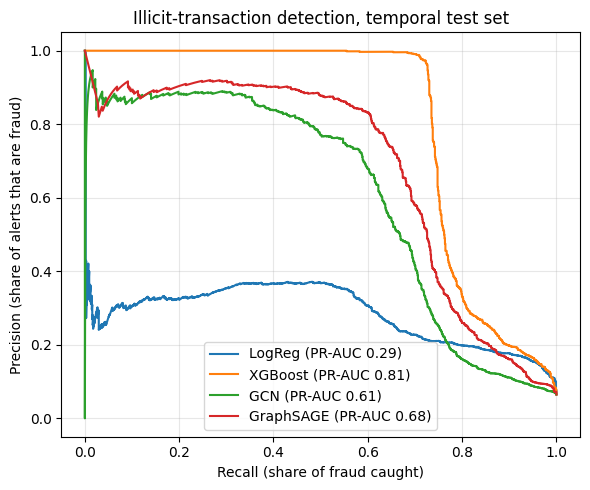

In [7]:
import pandas as pd
res = pd.DataFrame(results).set_index('model').round(3)
display(res)

plt.figure(figsize=(6,5))
for name, p in curves.items():
    pr, rc, _ = precision_recall_curve(yn[te], p)
    plt.plot(rc, pr, label=f"{name} (PR-AUC {average_precision_score(yn[te], p):.2f})")
plt.xlabel('Recall (share of fraud caught)'); plt.ylabel('Precision (share of alerts that are fraud)')
plt.title('Illicit-transaction detection, temporal test set'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig('pr_curves.png', dpi=150); plt.show()
res.to_csv('results.csv')

## 6. Error analysis: performance over time
The test period contains a known 'dark market shutdown' (around time step 43) after which fraud patterns change — a real example of **concept drift**.

/tmp/ipykernel_1026/790853669.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_t = df.groupby('t').apply(lambda g: f1_score(g.y, g.pred, zero_division=0))


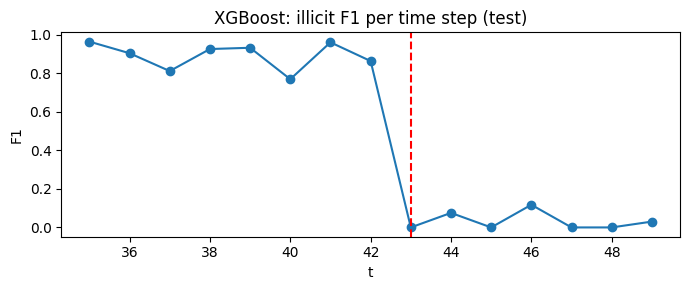

In [8]:
import pandas as pd
ts = pd.read_csv('data/elliptic/raw/elliptic_txs_features.csv', header=None, usecols=[1]).iloc[:,0].values
best_name = res['f1'].idxmax()
thr = res.loc[best_name, 'threshold']
pred = (curves[best_name] >= thr).astype(int)
df = pd.DataFrame({'t': ts[te], 'y': yn[te], 'pred': pred})
by_t = df.groupby('t').apply(lambda g: f1_score(g.y, g.pred, zero_division=0))
by_t.plot(marker='o', figsize=(7,3), title=f'{best_name}: illicit F1 per time step (test)')
plt.axvline(43, ls='--', c='r'); plt.ylabel('F1'); plt.tight_layout(); plt.savefig('f1_over_time.png', dpi=150); plt.show()

## 7. What to say about this project (fill in with YOUR numbers)
- **Problem:** detect illicit transactions in a 200k-node payment graph with ~10% positives.
- **Approach:** compared tabular baselines (LogReg, XGBoost) with GNNs (GCN, GraphSAGE); temporal split, train-only scaling, class weighting, threshold tuned on validation.
- **Result:** best model = ___ with illicit F1 ___ and PR-AUC ___.
- **Insight:** (fill in honestly) e.g. whether the graph helped vs XGBoost, and how all models dropped after the dark-market shutdown → concept drift; in production you'd monitor drift and retrain.
- **Next steps:** combine GNN embeddings with XGBoost; use edge features (amount, time); explain predictions with SHAP / GNNExplainer.